# Sentiment Analysis - YouTube Comments
**Nama**: Asep Haryana Saputra

## 1. Import Libraries

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense, Bidirectional, Dropout, SpatialDropout1D, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import resample
from tqdm.auto import tqdm

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.20.0


## 2. Data Loading & Preprocessing
**Target Classes**:
- 0: **Negative (Hujatan)**
- 1: **Positive (Apresiasi)**
- 2: **Spam (Promosi)**

In [13]:
# Nama file dataset
filename = 'dataset_youtube.csv'

if not os.path.exists(filename):
    raise FileNotFoundError(f"File {filename} not found! Please run the scraping script first.")

df = pd.read_csv(filename)
print(f"Loaded {len(df)} rows.")

# Auto-Labeling Function (Heuristic) - IMPROVED
def auto_label(text):
    text = str(text).lower()
    
    # SPAM Keywords
    spam_keywords = [
        'cek ig', 'promo', 'jual', 'obat', 'peninggi', 'pelangsing', 'subscribe', 'sub4sub', 
        'mampir', 'channel', 'link bio', 'giveaway', 'hadiah', 'gratis', 'follow', 'visit',
        'klik', 'top up', 'jasa', 'bisnis', 'wa', '08' 
    ]
    if any(k in text for k in spam_keywords):
        return 2 # Spam
        
    # POSITIVE Keywords
    pos_keywords = [
        'bagus', 'keren', 'mantap', 'semangat', 'good', 'nice', 'love', 'thanks', 'terima kasih', 
        'bermanfaat', 'membantu', 'suka', 'cool', 'best', 'hebat', 'lanjutkan', 'panutan', 'idol',
        'legend', 'terhibur', 'lucu', 'ngakak', 'kocak', 'anjay', 'anjing' if 'keren' in text else '@@@', 
        'gokil', 'pecah', 'trending', 'karyamu', 'support', 'wow', 'gas', 'menyala'
    ]
    if any(k in text for k in pos_keywords):
        return 1 # Positive
        
    # NEGATIVE Keywords
    neg_keywords = [
        'jelek', 'buruk', 'sampah', 'gagal', 'benci', 'hate', 'bad', 'stupid', 'idiot', 'bodoh', 
        'gajelas', 'malas', 'susah', 'ribet', 'unsub', 'cringe', 'alay', 'lebay', 'norak', 
        'garing', 'toxic', 'kontol', 'memek', 'anjing', 'bangsat', 'tolol', 'goblok', 'hujat', 'drama',
        'settingan', 'sampah', 'kecewa', 'merugikan', 'penipu', 'bohong', 'palsu'
    ]
    if any(k in text for k in neg_keywords):
        return 0 # Negative
        
    return -1 # Unlabeled

df['label'] = df['text'].apply(auto_label)

# Drop unlabeled data for training
df_clean = df[df['label'] != -1].copy()
print(f"Labeled Data Before Balancing: {len(df_clean)} rows")
print(df_clean['label'].value_counts())

# --- BALANCING DATA (Upsampling) ---
# Separate majority and minority classes
df_pos = df_clean[df_clean.label==1]
df_neg = df_clean[df_clean.label==0]
df_spam = df_clean[df_clean.label==2]

# Upsample minority classes
n_samples = len(df_pos) # Match majority class

df_neg_upsampled = resample(df_neg, 
                            replace=True,     # sample with replacement
                            n_samples=n_samples,    # to match majority class
                            random_state=42) 
                            
df_spam_upsampled = resample(df_spam, 
                             replace=True, 
                             n_samples=n_samples, 
                             random_state=42)

# Combine majority class with upsampled minority classes
df_balanced = pd.concat([df_pos, df_neg_upsampled, df_spam_upsampled])
df_clean = df_balanced # Replace working dataframe

print("\nAfter Balancing:")
print(df_clean['label'].value_counts())

df_clean.head()

Loaded 15000 rows.
Labeled Data Before Balancing: 8994 rows
label
1    7767
2    1010
0     217
Name: count, dtype: int64

After Balancing:
label
1    7767
0    7767
2    7767
Name: count, dtype: int64


,cid,text,time,author,votes,photo,heart,label
8,UgzKuphi4KVFn93bIDp4AaABAg,anjay,2 tahun yang lalu,@Wiibs,0,https://yt3.ggpht.com/jmLvvntMmr8qU6YLLUMWWkeG...,False,1
14,Ugy9Wbl4EuwXhZLvm194AaABAg,Bang buat trailer kocak piala Dunia qatar bang,3 tahun yang lalu,@ikokblekok3824,1,https://yt3.ggpht.com/ytc/AIdro_lTUbZwc_7nEjS9...,False,1
20,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D50kR-6hgg,Anjay,5 tahun yang lalu,@amofallo3543,19,https://yt3.ggpht.com/ytc/AIdro_mmvuRWeM_t6Nlt...,False,1
25,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D50hCN80YN,Anjay bang,5 tahun yang lalu,@vinoalfredo6153,165,https://yt3.ggpht.com/ytc/AIdro_l5UcvFMpSS3Qxn...,False,1
26,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D5IFfqW3YD,@vinoalfredo6153 gaya nya anjayyy,5 tahun yang lalu,@Rangga-ng1vg,1,https://yt3.ggpht.com/ytc/AIdro_k4cMxa8k9DkQ4S...,False,1


In [14]:
# Text Cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text) # Remove URLs
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text) # Remove special chars
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces
    return text

df_clean['cleaned_text'] = df_clean['text'].apply(clean_text)
df_clean = df_clean[df_clean['cleaned_text'].str.len() > 3] # Min length filter

## 3. Tokenization & Splitting

In [15]:
VOCAB_SIZE = 5000
MAX_LENGTH = 100
EMBEDDING_DIM = 64

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(df_clean['cleaned_text'])

sequences = tokenizer.texts_to_sequences(df_clean['cleaned_text'])
padded_sequences = pad_sequences(sequences, maxlen=MAX_LENGTH, padding='post', truncating='post')

X = padded_sequences
y = df_clean['label'].values

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (18585, 100), Test shape: (4647, 100)


## 4. Modeling (Bi-LSTM)

In [16]:
model = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(128, return_sequences=True)),
    Dropout(0.4),
    Bidirectional(LSTM(64)),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(3, activation='softmax') # 3 Output Classes
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

/home/asephs/venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Train
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[
        EarlyStopping(patience=5, restore_best_weights=True),
        ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-6)
    ]
)

Epoch 1/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8785 - loss: 0.2891 - val_accuracy: 0.9768 - val_loss: 0.0707 - learning_rate: 0.0010
Epoch 2/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9888 - loss: 0.0406 - val_accuracy: 0.9890 - val_loss: 0.0352 - learning_rate: 0.0010
Epoch 3/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9962 - loss: 0.0158 - val_accuracy: 0.9907 - val_loss: 0.0380 - learning_rate: 0.0010
Epoch 4/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9963 - loss: 0.0158 - val_accuracy: 0.9935 - val_loss: 0.0279 - learning_rate: 0.0010
Epoch 5/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.9977 - loss: 0.0096 - val_accuracy: 0.9929 - val_loss: 0.0317 - learning_rate: 0.0010
Epoch 6/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.9987 - loss: 0.0081 - val_accuracy: 0.9931 - val_loss: 0.0349 - learning_rate: 0.0010
Epoch 7/30
581/581 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - accuracy: 0.9994 - loss:

## 5. Evaluation

146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00      1554
    Positive       1.00      0.99      0.99      1552
        Spam       0.99      1.00      0.99      1541

    accuracy                           0.99      4647
   macro avg       0.99      0.99      0.99      4647
weighted avg       0.99      0.99      0.99      4647



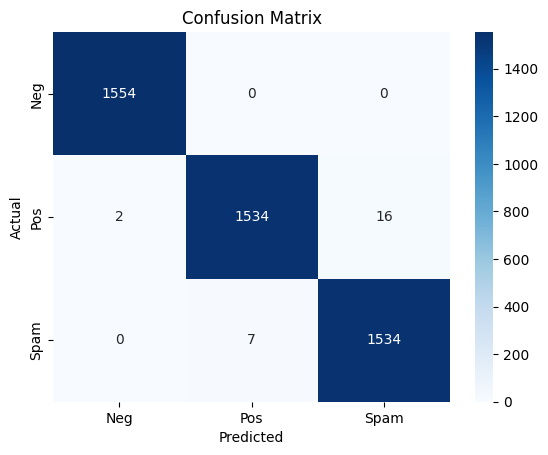

In [18]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive', 'Spam']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Neg', 'Pos', 'Spam'], yticklabels=['Neg', 'Pos', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()